In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from IPython.display import Audio
import scipy

# Convolution

Objective: ...

## Hands on

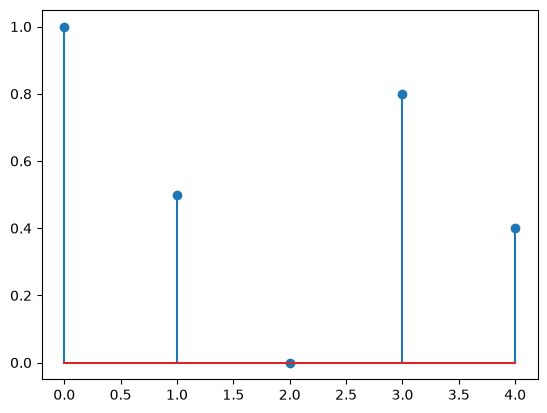

In [2]:
# create inputs
x = np.array([1, 0.5])
y = np.array([1, 0, 0, 0.8])

# convolve
z = np.convolve(x, y)

# plot
plt.stem(z);

## Convolution with an audio signal

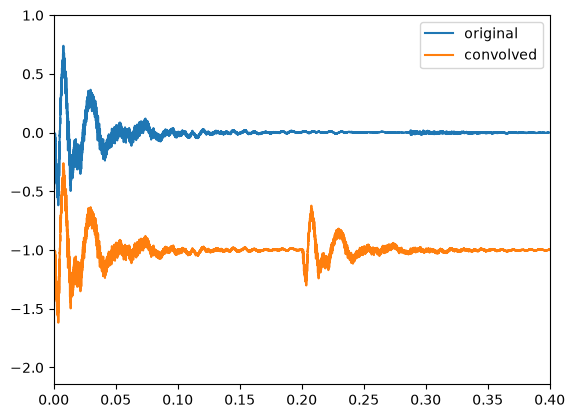

In [3]:
# load audio
fs, audio = scipy.io.wavfile.read('../assets/drums.wav')
audio = audio / np.max(np.abs(audio))

# convolve
delay_in_sec = 0.2
x = np.zeros(round(fs*delay_in_sec))
x[1] = 1; x[-1] = 0.5
audio_out = np.convolve(audio, x)

# play 
display(Audio(audio, rate=fs))

# plot
t = np.arange(len(audio))/fs
plt.plot(t, audio, label='original')
t = np.arange(len(audio_out))/fs
plt.plot(t, audio_out-1, label='convolved')
plt.xlim([0,2*delay_in_sec])
plt.legend()
plt.show()

# play 
display(Audio(audio_out, rate=fs))


## Convolution with an IR and an audio signal

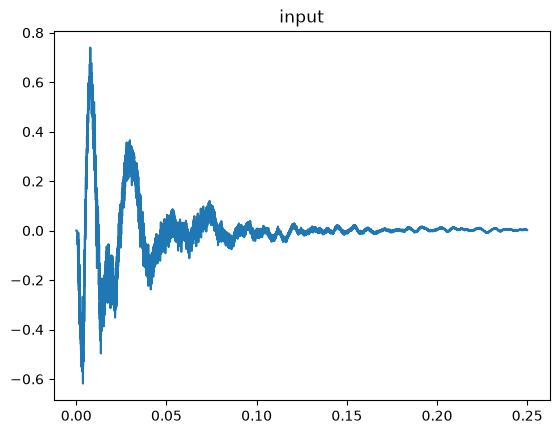

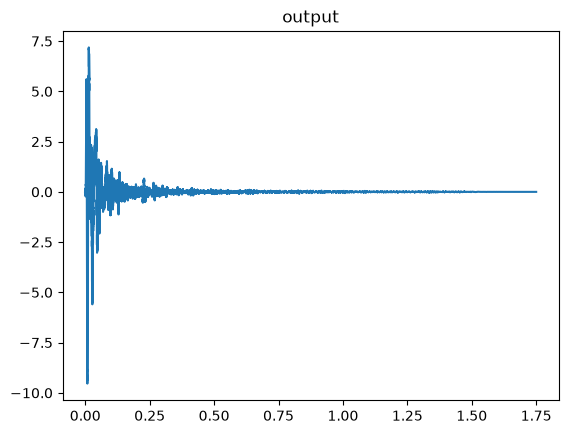

In [5]:
# load audio
fs, audio = scipy.io.wavfile.read('../assets/drums.wav')
fs_ir, ir = scipy.io.wavfile.read('../assets/ir_mono.wav')

# normalise 
audio = audio / np.max(np.abs(audio))
ir = ir / np.max(np.abs(ir))

# truncate (debug)
audio = audio[0:int(fs/4)]

# play 
display(Audio(audio, rate=fs))

# plot
t = np.arange(len(audio))/fs
plt.plot(t, audio)
plt.title('input')
plt.show()

# convolve
audio_out = np.convolve(audio, ir)

# play 
display(Audio(audio_out, rate=fs))

# plot
t = np.arange(len(audio_out))/fs
plt.plot(t, audio_out)
plt.title('output')
# plt.xlim([0,2*delay_in_sec])
plt.show()
